### **Connect Google Drive**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### **Import libraries, set seeds and load dataset**

In [2]:
# Set environment variables before importing TensorFlow
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

# Set random seeds for reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Enable deterministic TensorFlow operations
tf.config.experimental.enable_op_determinism()

# Image size used by all models
IMG_SIZE = (224, 224)

# Number of images processed at one time
BATCH_SIZE = 16

# Balanced dataset paths in Google Drive
TRAIN_DIR = "/content/drive/MyDrive/Dataset/Lung_Cancer_Augmented_Dataset_V2/train"
VAL_DIR = "/content/drive/MyDrive/Dataset/Lung_Cancer_Augmented_Dataset_V2/valid"
TEST_DIR = "/content/drive/MyDrive/Dataset/Lung_Cancer_Augmented_Dataset_V2/test"

# Load training images and labels
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Load validation images
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load testing images
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Store class names before modifying datasets
class_names = train_ds.class_names

# Verify that all datasets have the same class order
assert train_ds.class_names == val_ds.class_names
assert train_ds.class_names == test_ds.class_names

print("Class names:", class_names)

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)

# Set deterministic dataset processing
options = tf.data.Options()
options.experimental_deterministic = True

train_ds = train_ds.with_options(options)
val_ds = val_ds.with_options(options)
test_ds = test_ds.with_options(options)

# Prefetch helps load the next batch while the model trains
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("\nDataset loading completed!")

Found 2205 files belonging to 3 classes.
Found 289 files belonging to 3 classes.
Found 292 files belonging to 3 classes.
Class names: ['Benign', 'Malignant', 'Normal']
Number of classes: 3

Dataset loading completed!


### **Build CNN models**

In [3]:
from tensorflow.keras import layers, models

# Import six pretrained CNN architectures
from tensorflow.keras.applications import (
    MobileNetV2,
    VGG16,
    InceptionV3,
    EfficientNetB0,
    DenseNet121,
    ResNet50
)

# Import preprocessing functions for each model
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess


def build_model(model_name):

    # Select CNN architecture and its preprocessing function

    if model_name == "ResNet50":

        base_model = ResNet50(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMG_SIZE, 3)
        )

        preprocess = resnet_preprocess

    elif model_name == "DenseNet121":

        base_model = DenseNet121(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMG_SIZE, 3)
        )

        preprocess = densenet_preprocess

    elif model_name == "EfficientNetB0":

        base_model = EfficientNetB0(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMG_SIZE, 3)
        )

        preprocess = efficientnet_preprocess

    elif model_name == "InceptionV3":

        base_model = InceptionV3(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMG_SIZE, 3)
        )

        preprocess = inception_preprocess

    elif model_name == "MobileNetV2":

        base_model = MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMG_SIZE, 3)
        )

        preprocess = mobilenet_preprocess

    elif model_name == "VGG16":

        base_model = VGG16(
            weights="imagenet",
            include_top=False,
            input_shape=(*IMG_SIZE, 3)
        )

        preprocess = vgg_preprocess

    else:
        raise ValueError("Unknown model name: " + model_name)

    # Freeze pretrained CNN layers initially
    base_model.trainable = False

    # Build classification head
    inputs = layers.Input(shape=(*IMG_SIZE, 3))

    x = layers.Lambda(preprocess)(inputs)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = models.Model(inputs, outputs)

    # Compile the model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

### **Train Dataset**

In [4]:
import pandas as pd
import os

# Import callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Folder to save trained models in Google Drive
MODEL_SAVE_DIR = "/content/drive/MyDrive/Lung_Cancer_Trained_Models"

os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

# Store results and trained models
results = []
trained_models = {}
trained_histories = {}

# Six CNN architectures
MODEL_NAMES = [
    "ResNet50",
    "EfficientNetB0",
    "MobileNetV2",
    "DenseNet121",
    # "VGG16"
    # "InceptionV3",
]

# Train each model
for name in MODEL_NAMES:

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    # Reset random seeds before each model
    tf.keras.utils.set_random_seed(SEED)

    # Build a fresh model
    model = build_model(name)

    # Temporary checkpoint location
    checkpoint_path = f"/content/{name}_best.keras"

    # Training callbacks
    callbacks = [

        # Stop training if validation loss stops improving
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),

        # Save the best model based on validation loss
        ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    # Train the model
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        callbacks=callbacks,
        verbose=1
    )

    trained_histories[name] = history

    # Evaluate the model on test dataset
    test_loss, test_accuracy = model.evaluate(
        test_ds,
        verbose=1
    )

    print(
        name,
        "Test Accuracy:",
        round(test_accuracy * 100, 2),
        "%"
    )

    # Save the trained model in Google Drive
    save_path = os.path.join(
        MODEL_SAVE_DIR,
        f"{name}_best.keras"
    )

    model.save(save_path)

    print("Model saved:", save_path)

    # Keep trained model for future evaluation
    trained_models[name] = model

    # Store model performance
    results.append({

        "Model": name,

        "Test Accuracy (%)": round(
            test_accuracy * 100, 2
        ),

        "Test Loss": round(
            test_loss, 4
        ),

        "Best Validation Accuracy (%)": round(
            max(history.history["val_accuracy"]) * 100, 2
        ),

        "Epochs Trained": len(history.history["loss"])
    })


# Create comparison table
results_df = pd.DataFrame(results)

print("\n========== MODEL COMPARISON ==========")

display(results_df)

# Save comparison results in Google Drive
results_df.to_csv(
    os.path.join(MODEL_SAVE_DIR, "model_comparison.csv"),
    index=False
)

print("\nAll models trained successfully!")
print("Models and comparison results saved in Google Drive!")


Training: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6893 - loss: 0.7463
Epoch 1: val_loss improved from None to 0.30539, saving model to /content/ResNet50_best.keras

Epoch 1: finished saving model to /content/ResNet50_best.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.7918 - loss: 0.4848 - val_accuracy: 0.8789 - val_loss: 0.3054
Epoch 2/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9001 - loss: 0.2376
Epoch 2: val_loss improved from 0.30539 to 0.25905, saving model to /content/ResNet50_best.keras

Epoch 2: finished saving model to /content/ResNet50_best.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 13s 97ms/step - accuracy: 0.8961 - loss: 0.2382 - val_accuracy: 0.8858 - val_loss: 0.2590
Epoch 3/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.9100 - loss: 0.2127
Epoch 3: val_loss improved from 0.25905 to 0.24808, saving model to /content/ResNet50_best.keras

Epoch 3: finishe

,Model,Test Accuracy (%),Test Loss,Best Validation Accuracy (%),Epochs Trained
0,ResNet50,92.12,0.2064,91.70,10
1,EfficientNetB0,89.04,0.2533,91.70,10
2,MobileNetV2,91.10,0.2543,93.08,10
3,DenseNet121,86.64,0.2952,90.31,10



All models trained successfully!
Models and comparison results saved in Google Drive!


## **Model evaluation and comparison**

In [5]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Collect actual labels from the test dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Store predictions of all models
all_predictions = {}

# Collect actual validation labels
val_y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

# Store validation predictions
all_val_predictions = {}

# Store model comparison results
comparison = []

# Evaluate every trained model
for name, model in trained_models.items():

    print("\nEvaluating:", name)

    # Predict class probabilities
    probabilities = model.predict(test_ds, verbose=0)

    # Convert probabilities into predicted class labels
    y_pred = np.argmax(probabilities, axis=1)

    # Store predictions for future evaluation
    all_predictions[name] = probabilities

    # Predict validation probabilities
    val_probabilities = model.predict(val_ds, verbose=0)

    # Convert validation probabilities into class labels
    val_pred = np.argmax(val_probabilities, axis=1)

    # Store validation predictions
    all_val_predictions[name] = val_probabilities

    # Calculate performance metrics
    comparison.append({

        "Model": name,

        "Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ),

        "Precision (%)": round(
            precision_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            ) * 100, 2
        ),

        "Recall (%)": round(
            recall_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            ) * 100, 2
        ),

        "F1-score (%)": round(
            f1_score(
                y_true, y_pred,
                average="macro",
                zero_division=0
            ) * 100, 2
        ),

        "Validation Macro F1 (%)": round(
            f1_score(
                val_y_true,
                val_pred,
                average="macro",
                zero_division=0
            ) * 100, 2
        ),
    })


# Create comparison DataFrame
comparison_df = pd.DataFrame(comparison)

# Sort models by macro F1-score
comparison_df = comparison_df.sort_values(
    by="F1-score (%)",
    ascending=False
).reset_index(drop=True)

# Display comparison results
print("\n========== CNN MODEL COMPARISON ==========")

display(comparison_df)

# Save comparison results in Google Drive
comparison_df.to_csv(
    "/content/drive/MyDrive/Lung_Cancer_Trained_Models/cnn_model_comparison.csv",
    index=False
)

print("Comparison results saved successfully!")


Evaluating: ResNet50

Evaluating: EfficientNetB0

Evaluating: MobileNetV2

Evaluating: DenseNet121

========== CNN MODEL COMPARISON ==========


,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),Validation Macro F1 (%)
0,ResNet50,92.12,92.41,91.79,92.08,91.67
1,MobileNetV2,91.10,91.82,90.12,90.86,92.94
2,EfficientNetB0,89.04,89.21,88.85,89.03,91.80
3,DenseNet121,86.64,87.46,85.05,85.97,88.28


Comparison results saved successfully!


## **Performance comparison graph**

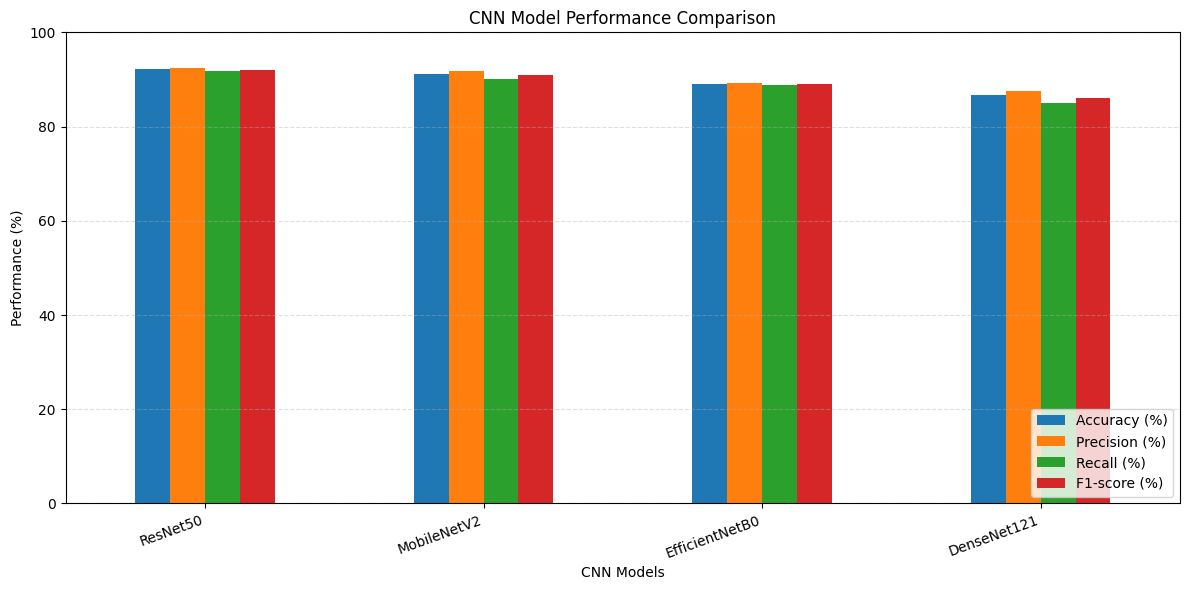

In [6]:
import matplotlib.pyplot as plt

# Plot all performance metrics together
comparison_df.plot(
    x="Model",
    y=[
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-score (%)"
    ],
    kind="bar",
    figsize=(12, 6)
)

plt.title("CNN Model Performance Comparison")
plt.ylabel("Performance (%)")
plt.xlabel("CNN Models")

plt.ylim(0, 100)

plt.xticks(rotation=20, ha="right")

plt.legend(loc="lower right")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## **Best model, classification report and confusion matrix**

Best model by Macro F1-score: MobileNetV2

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Benign     0.8571    0.7606    0.8060        71
   Malignant     0.8976    0.9430    0.9198       158
      Normal     1.0000    1.0000    1.0000        63

    accuracy                         0.9110       292
   macro avg     0.9182    0.9012    0.9086       292
weighted avg     0.9099    0.9110    0.9094       292



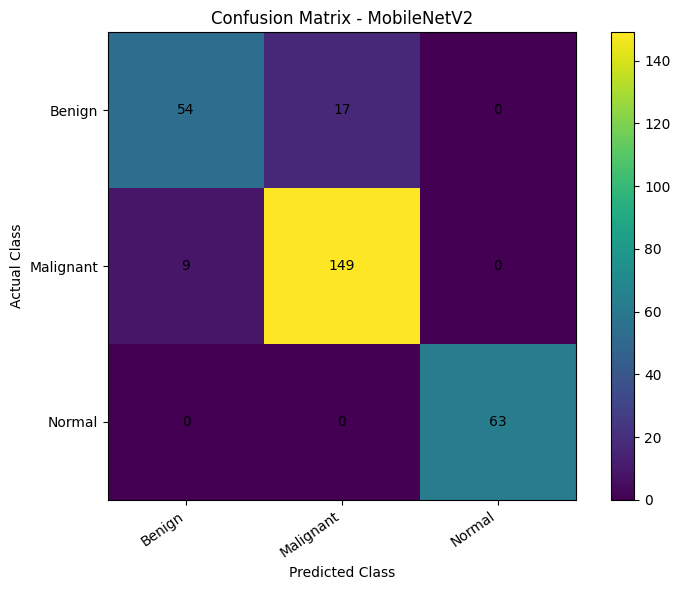

In [7]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
# -----------------------------------------------------
# Select the model with the highest macro F1-score
# best_name = comparison_df.iloc[0]["Model"]

# best_model = trained_models[best_name]
# -----------------------------------------------------

# Select best model using validation macro F1-score
best_name = comparison_df.sort_values(
    by="Validation Macro F1 (%)",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_name]

print("Best model by Macro F1-score:", best_name)

# Get stored predictions of the best model
probabilities = all_predictions[best_name]

# Convert probabilities into predicted classes
y_pred = np.argmax(probabilities, axis=1)


# Classification Report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0,
    digits=4
))


# Confusion Matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(8, 6))

plt.imshow(cm, interpolation="nearest")

plt.title(f"Confusion Matrix - {best_name}")

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    class_names,
    rotation=35,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Display values inside the matrix
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

## **ROC Curve and AUC analysis**

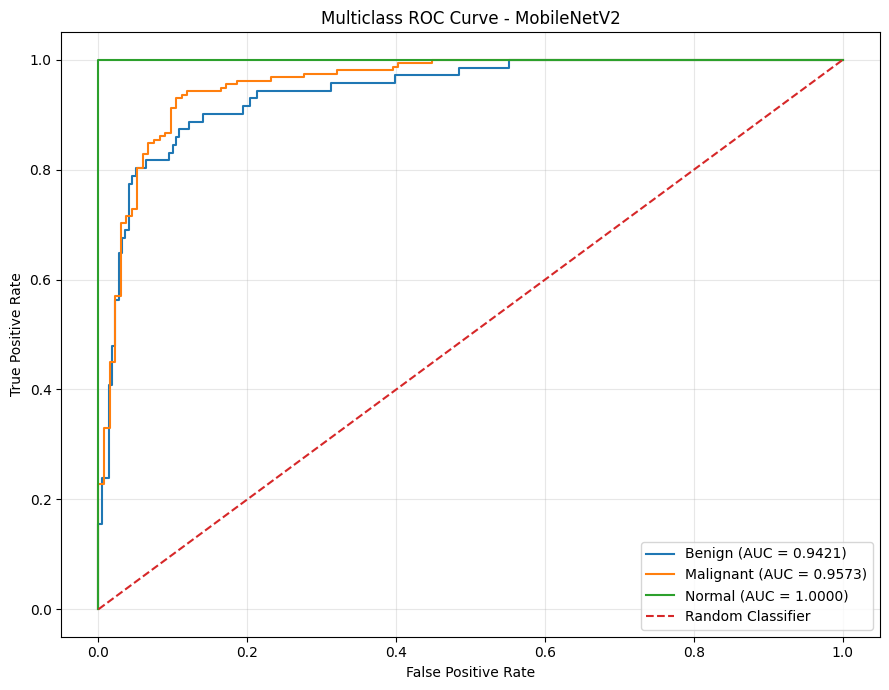

In [8]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Select the best model's prediction probabilities
best_probabilities = all_predictions[best_name]

# Convert actual labels into binary format
# Required for multiclass ROC analysis
y_true_binary = label_binarize(
    y_true,
    classes=list(range(NUM_CLASSES))
)

# Plot ROC curve for each class
plt.figure(figsize=(9, 7))

for i, class_name in enumerate(class_names):

    # Calculate False Positive Rate and True Positive Rate
    fpr, tpr, thresholds = roc_curve(
        y_true_binary[:, i],
        best_probabilities[:, i]
    )

    # Calculate AUC score
    roc_auc = auc(fpr, tpr)

    # Draw ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.4f})"
    )

# Random prediction baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(f"Multiclass ROC Curve - {best_name}")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

## **Underfitting and Overfitting analysis**

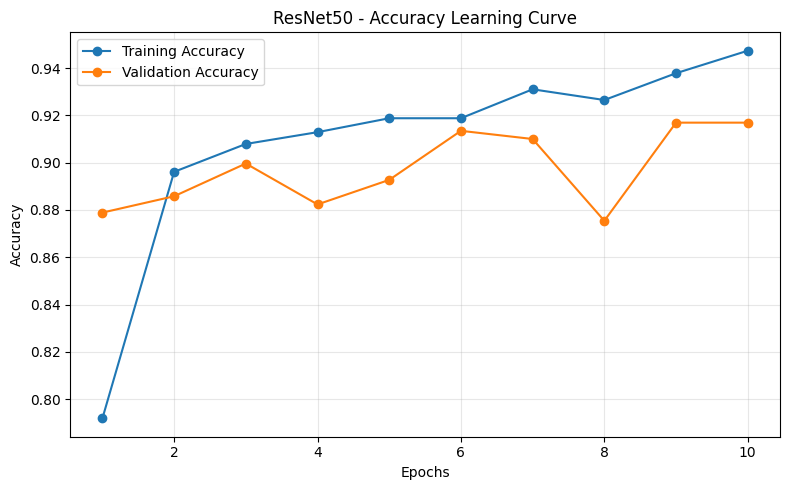

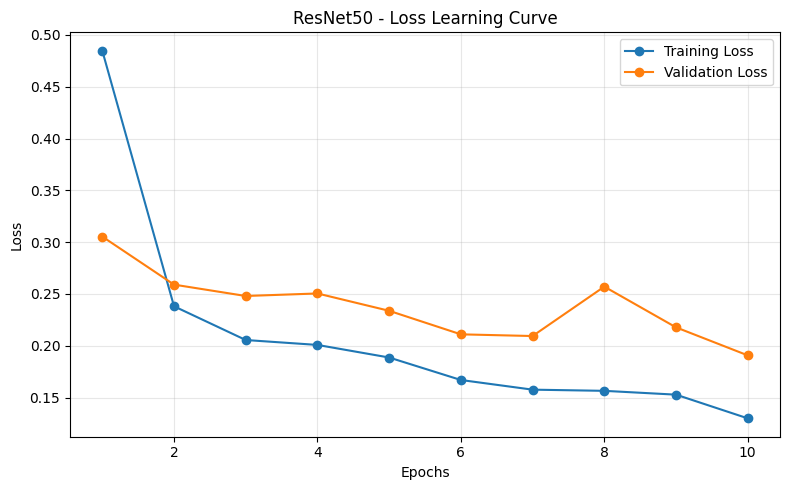

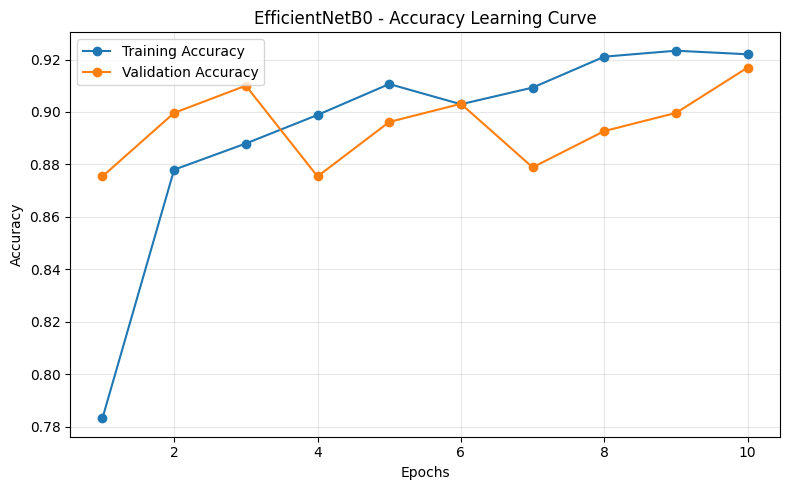

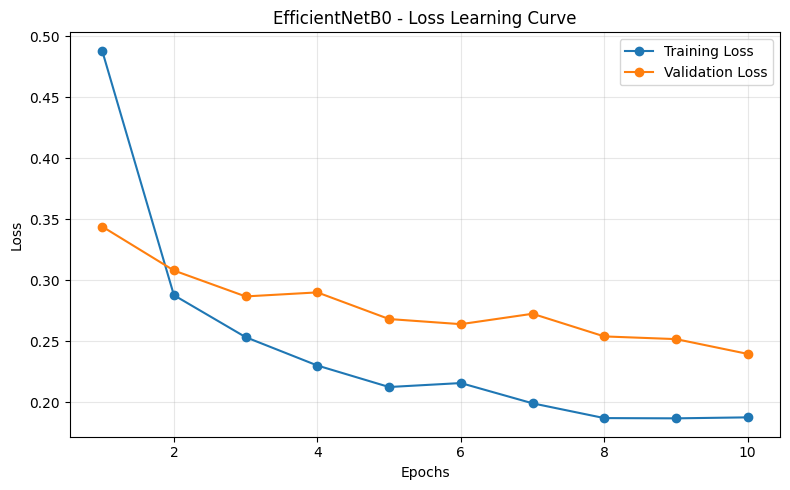

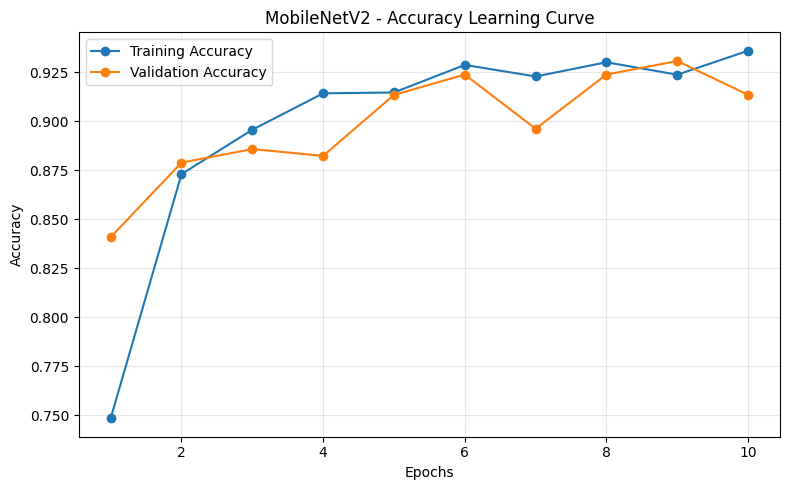

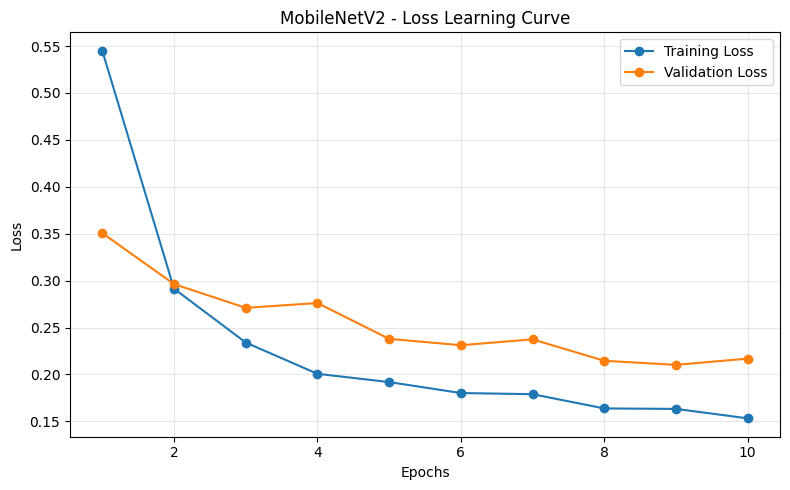

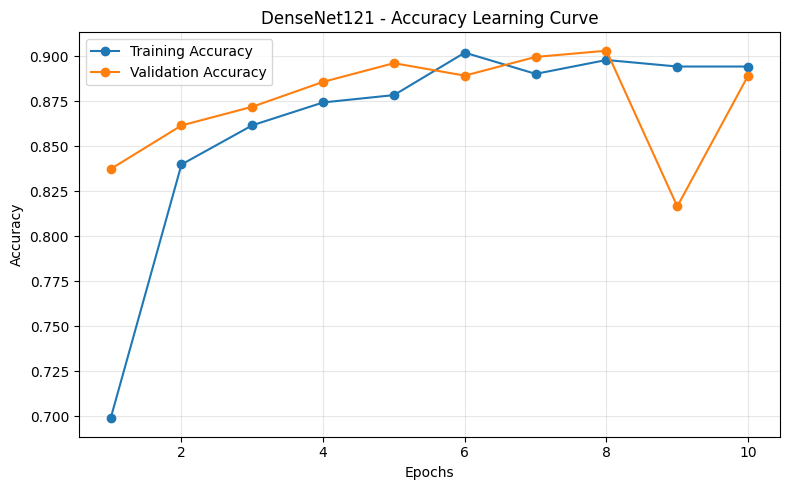

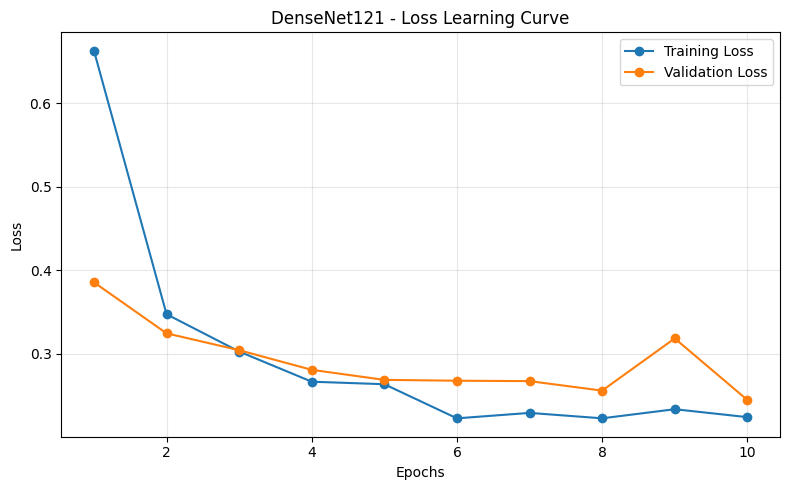

In [9]:
import matplotlib.pyplot as plt

# Analyze learning curves for all trained models
for name, history in trained_histories.items():

    # Get training and validation metrics
    train_acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]

    train_loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs_range = range(1, len(train_acc) + 1)


    # ==================================
    # 1. Accuracy Learning Curve
    # ==================================

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs_range,
        train_acc,
        marker="o",
        label="Training Accuracy"
    )

    plt.plot(
        epochs_range,
        val_acc,
        marker="o",
        label="Validation Accuracy"
    )

    plt.title(f"{name} - Accuracy Learning Curve")

    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


    # ==================================
    # 2. Loss Learning Curve
    # ==================================

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs_range,
        train_loss,
        marker="o",
        label="Training Loss"
    )

    plt.plot(
        epochs_range,
        val_loss,
        marker="o",
        label="Validation Loss"
    )

    plt.title(f"{name} - Loss Learning Curve")

    plt.xlabel("Epochs")
    plt.ylabel("Loss")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()